# Theoretical Model

In [1]:
%pip install numpy matplotlib

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

Note: you may need to restart the kernel to use updated packages.


# The model

- the three groups and their settings

- swarmalator and Couzin movement

- adaptive coupling, with the friendship floor

- the song oscillator with its layered pull and hook

- fog

- all measures: R, S, local synchrony, leadership and mean coupling

To create a group, write DanceFloor('strangers', seed=0). You can override any parameter by name, for example DanceFloor('friends', seed=3, F=0.8, mem=15).

In [2]:
TAU = 2 * np.pi
RF = 2.2      # floor radius (model units)
DT = 0.02     # integration step (s)

BASE = dict(N=16, f0=1.0, sigma=0.25, K=0.9, J=0.5, v0=0.0, noise=0.08, mode='swarm',
            adaptive=False, eps=0.15, beta=0.0, k0=0.3, kf=0.9, kf_min=0.6,
            loop=True, F=1.1, tau=0.15, Km=2.0, rise=1.0, mem=6.0,
            wB=0.6, wH=0.25, wM=0.15, fog_cut=0.85)

GROUPS = {
    'strangers': dict(K=1.0, sigma=0.2, J=0.2, noise=0.08, adaptive=True, eps=0.08, k0=0.1, F=1.3),
    'pros':      dict(K=1.2, sigma=0.06, J=0.5, noise=0.03, adaptive=False, F=1.6),
    'friends':   dict(K=1.0, sigma=0.2, J=0.6, noise=0.08, adaptive=True, eps=0.08, k0=0.1, kf=0.9, F=1.3),
}

def clarity(R):
    return 1 / (1 + np.exp(-(R - 0.45) / 0.07))

def ramp(x, a, b):
    return min(1.0, max(0.0, (x - a) / (b - a)))

def wrap(a):
    return np.arctan2(np.sin(a), np.cos(a))


class DanceFloor:
    def __init__(self, group='strangers', seed=0, **overrides):
        self.P = {**BASE, **GROUPS.get(group, {}), **overrides}
        self.group = group
        self.rng = np.random.default_rng(seed)
        self.t = 0.0
        self.fog = []
        self.spawn()

    #setup
    def spawn(self):
        P, rng, n = self.P, self.rng, self.P['N']
        r = np.sqrt(rng.random(n)) * 1.6
        a = rng.random(n) * TAU
        self.x = np.c_[r * np.cos(a), r * np.sin(a)]
        self.ph = rng.random(n) * TAU          # heading
        self.th = rng.random(n) * TAU          # movement phase
        self.z0 = rng.standard_normal(n)       # tempo deviation
        self.fg = np.full(n, -1)               # friend group (-1 = none)
        if self.group == 'friends':
            i, g = 0, 0
            while i < n:
                size = min(n - i, 2 + rng.integers(0, 3))
                rr, an, gz = np.sqrt(rng.random()) * 1.3, rng.random() * TAU, rng.standard_normal()
                for _ in range(size):
                    b = rng.random() * TAU
                    self.fg[i] = g
                    self.x[i] = [rr * np.cos(an) + 0.3 * np.cos(b), rr * np.sin(an) + 0.3 * np.sin(b)]
                    self.z0[i] = 0.9 * gz + 0.44 * rng.standard_normal()
                    i += 1
                g += 1
        self.friends = (self.fg[:, None] == self.fg[None, :]) & (self.fg[:, None] >= 0) & ~np.eye(n, dtype=bool)
        self.reset_coupling()
        self.loc = np.zeros(n)
        self.lead = np.zeros(n)
        self.song = dict(ph=0.0, G=0.0, q=0, chord=0, hook=0.0, D=0.0, layers=(0, 0, 0), degs=[0, 1, 2, 1, 0, -1])
        self.hist = np.zeros((64, 2))          # delayed (song phase, musical pull)
        self.hi = 0
        self.measure()

    def reset_coupling(self):
        P, n = self.P, self.P['N']
        if P['adaptive']:
            self.Kij = np.where(self.friends, P['kf'], P['k0']).astype(float)
        else:
            self.Kij = np.ones((n, n))
        np.fill_diagonal(self.Kij, 0)

    #measures 
    def measure(self):
        z = np.exp(1j * self.th).mean()
        self.R, self.psi = abs(z), np.angle(z)
        c = self.x.mean(0)
        phi = np.arctan2(self.x[:, 1] - c[1], self.x[:, 0] - c[0])
        self.S = max(abs(np.exp(1j * (phi + self.th)).mean()), abs(np.exp(1j * (phi - self.th)).mean()))
        n = self.P['N']
        self.Kbar = self.Kij.sum() / (n * (n - 1))

    def local_measures(self):
        d = np.linalg.norm(self.x[None, :, :] - self.x[:, None, :], axis=2)
        w = np.exp(-d / 0.7)
        np.fill_diagonal(w, 0)
        dth = self.th[None, :] - self.th[:, None]
        r = np.abs((w * np.exp(1j * dth)).sum(1)) / w.sum(1)
        lead = (w * np.sin(-dth)).sum(1) / w.sum(1)
        self.loc += (r - self.loc) * 0.25
        self.lead += (lead - self.lead) * 0.15
        self.local = self.loc.mean()

    #fog 
    def add_fog(self, px, pz):
        self.fog.append([px, pz, 0.0])

    def fog_at(self):
        f = np.zeros(self.P['N'])
        for px, pz, age in self.fog:
            dens = np.exp(-age / 9) * min(1, age / 0.6)
            rad = 0.45 + 0.55 * (1 - np.exp(-age / 3))
            d2 = (self.x[:, 0] - px) ** 2 + (self.x[:, 1] - pz) ** 2
            f += dens * np.exp(-d2 / rad ** 2)
        return np.minimum(1, f)

    #music
    def song_bar(self):
        s, rng = self.song, self.rng
        G = s['G']
        if G > 0.4:
            s['chord'] = (s['chord'] + 1) % 4
        if rng.random() < 0.08 + 0.5 * (1 - G):
            if G < 0.3 or rng.random() < 0.3:
                s['hook'] = 0.0
            else:
                s['hook'] *= 0.5
        else:
            s['hook'] += (1 - s['hook']) * 0.35

    def song_step(self):
        P, s = self.P, self.song
        s['ph'] += DT * (TAU * P['f0'] + P['Km'] * self.R * np.sin(self.psi - s['ph']))
        cl = clarity(self.R)
        s['G'] += DT * (cl - s['G']) / (P['rise'] if cl > s['G'] else max(0.2, P['mem']))
        q = int(np.floor(s['ph'] / (TAU / 4)))
        while s['q'] < q:
            s['q'] += 1
            if s['q'] % 16 == 0:
                self.song_bar()
        p_, h_, m_ = ramp(s['G'], .15, .6), ramp(s['G'], .4, .8), ramp(s['G'], .45, .85) * s['hook']
        s['layers'] = (p_, h_, m_)
        s['D'] = P['wB'] * p_ + P['wH'] * h_ + P['wM'] * m_
        self.hist[self.hi % 64] = (s['ph'], s['D'])
        self.hi += 1
        lag = min(63, round(P['tau'] / DT))
        ph_d, D_d = self.hist[(self.hi - 1 - lag) % 64]
        return ph_d + TAU * P['f0'] * P['tau'], D_d

    #one step
    def step(self):
        P, n, rng = self.P, self.P['N'], self.rng
        self.measure()
        heard_ph, pull = self.song_step()

        rel = self.x[None, :, :] - self.x[:, None, :]          # rel[i, j] = x_j - x_i
        d = np.linalg.norm(rel, axis=2) + 1e-6
        dth = self.th[None, :] - self.th[:, None]               # theta_j - theta_i
        f = self.fog_at()
        vis = (1 - P['fog_cut'] * f)[:, None] * (1 - P['fog_cut'] * f)[None, :]
        c, s = np.cos(dth) * vis, np.sin(dth)

        omega = TAU * (P['f0'] + P['sigma'] * self.z0)
        sp = (self.Kij * s * vis / np.maximum(d, 0.2)).sum(1)
        dtheta = omega + P['K'] / n * sp
        if P['loop']:
            dtheta += P['F'] * pull * np.sin(heard_ph - self.th)

        unit = rel / d[:, :, None]
        if P['mode'] == 'swarm':
            attract = unit * (1 + P['J'] * c)[:, :, None]
            repel = rel / np.maximum(d * d, 0.01)[:, :, None]
            v = (attract - repel).sum(1) / n
            v += P['v0'] * np.c_[np.cos(self.ph), np.sin(self.ph)]
            dph = np.zeros(n)
            if P['v0'] > 0:
                w = np.exp(-d / 0.8)
                np.fill_diagonal(w, 0)
                dph = 1.5 * (w * np.sin(self.ph[None, :] - self.ph[:, None])).sum(1) / w.sum(1)
        else:
            eye = np.eye(n, dtype=bool)
            rep = (d < 0.3) & ~eye
            ali = (d >= 0.3) & (d < 0.8)
            att = (d >= 0.8) & (d < 1.8)
            want = np.where(rep.any(1)[:, None], -(unit * rep[:, :, None]).sum(1),
                            (np.c_[np.cos(self.ph), np.sin(self.ph)][None, :, :] * ali[:, :, None]).sum(1)
                            + (unit * (att * (1 + P['J'] * c))[:, :, None]).sum(1))
            none = (np.abs(want).sum(1) == 0)
            want[none] = np.c_[np.cos(self.ph), np.sin(self.ph)][none]
            turn = wrap(np.arctan2(want[:, 1], want[:, 0]) - self.ph)
            dph = np.clip(turn * 4, -3, 3)
            v = (0.35 + P['v0']) * np.c_[np.cos(self.ph), np.sin(self.ph)]

        rr = np.linalg.norm(self.x, axis=1)
        out = rr > RF * 0.88
        v[out] -= (self.x[out] / rr[out, None]) * ((rr[out] - RF * 0.88) * 4)[:, None]
        if P['mode'] == 'couzin':
            dph[out] += wrap(np.arctan2(-self.x[out, 1], -self.x[out, 0]) - self.ph[out]) * 2

        if P['adaptive']:
            self.Kij += P['eps'] * DT * (np.cos(dth + P['beta']) - self.Kij)
            self.Kij = np.clip(self.Kij, -1, 1)
            self.Kij = np.where(self.friends, np.maximum(self.Kij, P['kf_min']), self.Kij)
            np.fill_diagonal(self.Kij, 0)

        self.th += dtheta * DT + np.sqrt(2 * P['noise'] * DT) * rng.standard_normal(n)
        self.x += v * DT
        self.ph += dph * DT + (0.3 * np.sqrt(DT) * rng.standard_normal(n) if (P['mode'] == 'couzin' or P['v0'] > 0) else 0)
        for puff in self.fog:
            puff[2] += DT
        self.fog = [p for p in self.fog if p[2] <= 30]
        self.t += DT

    #run
    def run(self, seconds, record_every=0.1, sweep=None):
        """Run the model and return a dict of time series sampled every record_every seconds."""
        out = {k: [] for k in ['t', 'R', 'S', 'Kbar', 'local', 'G', 'pull', 'K']}
        steps, every = int(round(seconds / DT)), int(round(record_every / DT))
        for k in range(steps):
            if sweep is not None:
                self.P['K'] = sweep(k * DT)
            self.step()
            if (k + 1) % every == 0:
                self.local_measures()
                for key, val in [('t', self.t), ('R', self.R), ('S', self.S), ('Kbar', self.Kbar), ('local', self.local),
                                 ('G', self.song['G']), ('pull', self.song['D']), ('K', self.P['K'])]:
                    out[key].append(val)
        return {k: np.array(v) for k, v in out.items()}

# Run one group and watch it over time

This runs three minutes of strangers and plots three panels:

- synchrony, global and local

- the song strength G and the musical pull M the dancers hear

- the mean learned coupling

In seed 1 the group wanders apart for about 20 seconds. Then the song rises sharply, synchrony jumps above 0.6, and the learned ties climb after it.

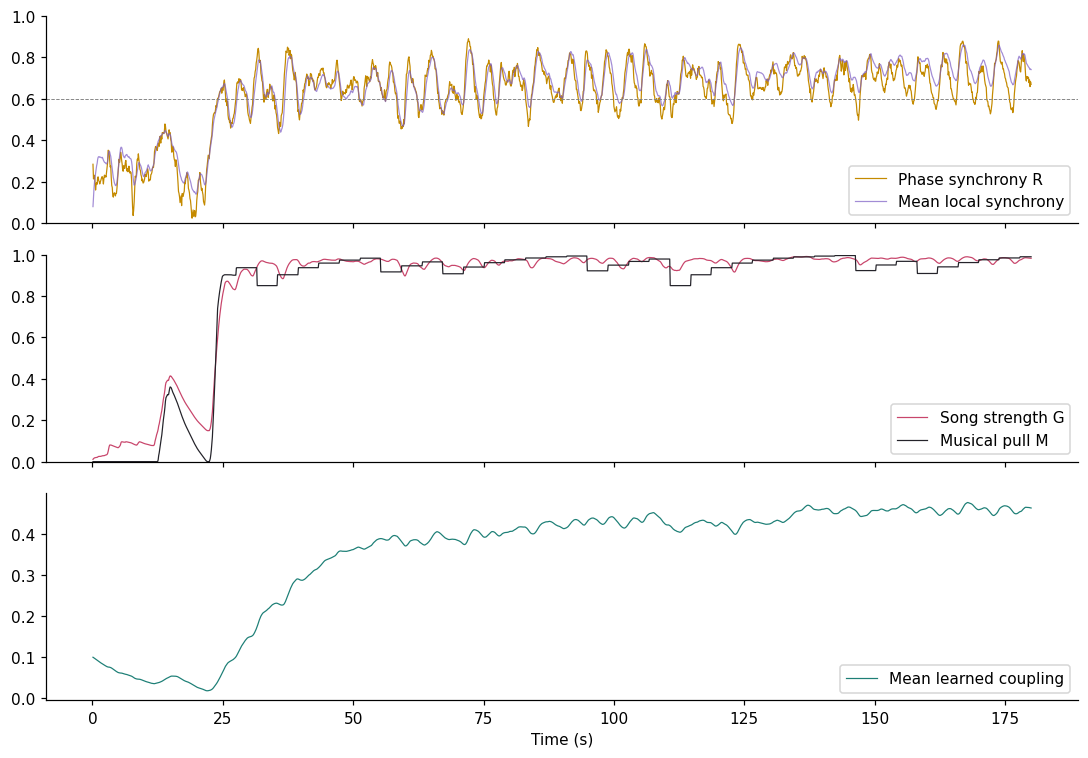

In [3]:
m = DanceFloor('strangers', seed=1)
out = m.run(180)

fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
ax[0].plot(out['t'], out['R'], color='#c48a00', lw=0.8, label='Phase synchrony R')
ax[0].plot(out['t'], out['local'], color='#7b5cc4', lw=0.8, alpha=0.7, label='Mean local synchrony')
ax[0].axhline(0.6, color='gray', ls='--', lw=0.6); ax[0].set_ylim(0, 1); ax[0].legend(loc='lower right')
ax[1].plot(out['t'], out['G'], color='#c8456b', lw=0.8, label='Song strength G')
ax[1].plot(out['t'], out['pull'], color='#24232a', lw=0.8, label='Musical pull M')
ax[1].set_ylim(0, 1); ax[1].legend(loc='lower right')
ax[2].plot(out['t'], out['Kbar'], color='#1d7f76', lw=0.8, label='Mean learned coupling')
ax[2].set_xlabel('Time (s)'); ax[2].legend(loc='lower right')
plt.tight_layout(); plt.show()

# A snapshot of the floor

This draws the floor from above, using the same visual language as the website:

- Dancer color: each dancer in the heat colors of its local synchrony.

- Teal lines: strong learned ties.

- Triangles: leaders.

- Gray circles: fog.

You can call show_floor(m) at any point after running a model.

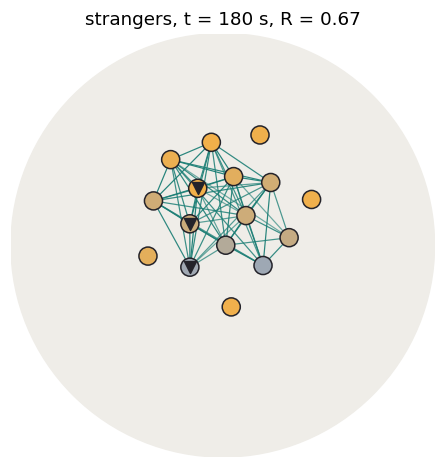

In [4]:
def heat(v):
    stops = [(0, '#c3ccd8'), (0.6, '#8ea6c8'), (0.8, '#f2b04a'), (0.93, '#e2632b'), (1, '#b31d2c')]
    from matplotlib.colors import LinearSegmentedColormap
    return LinearSegmentedColormap.from_list('heat', stops)(np.clip(v, 0, 1))

def show_floor(m, title=''):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.add_patch(plt.Circle((0, 0), RF, color='#efede8', zorder=0))
    n = m.P['N']
    if m.P['adaptive']:
        for i in range(n):
            for j in range(i + 1, n):
                k = (m.Kij[i, j] + m.Kij[j, i]) / 2
                if k > 0.6 and np.linalg.norm(m.x[i] - m.x[j]) < 1.6:
                    ax.plot(*zip(m.x[i], m.x[j]), color='#1d7f76', alpha=min(1, k), lw=0.8, zorder=1)
    ax.scatter(m.x[:, 0], m.x[:, 1], s=140, c=heat(m.loc), edgecolors='#24232a', zorder=2)
    leaders = np.argsort(-m.lead)[:3]
    for i in leaders:
        if m.lead[i] > 0.2 and m.loc[i] > 0.6:
            ax.scatter(*m.x[i], marker='v', s=60, color='#24232a', zorder=3)
    for px, pz, age in m.fog:
        ax.add_patch(plt.Circle((px, pz), 0.45 + 0.55 * (1 - np.exp(-age / 3)), color='gray', alpha=0.25 * np.exp(-age / 9)))
    ax.set_xlim(-RF, RF); ax.set_ylim(-RF, RF); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title or f'{m.group}, t = {m.t:.0f} s, R = {m.R:.2f}')
    return ax

show_floor(m); plt.show()

# Compare the three groups

This runs eight groups of each kind for two minutes, plots their synchrony side by side, and counts how many found a shared beat.

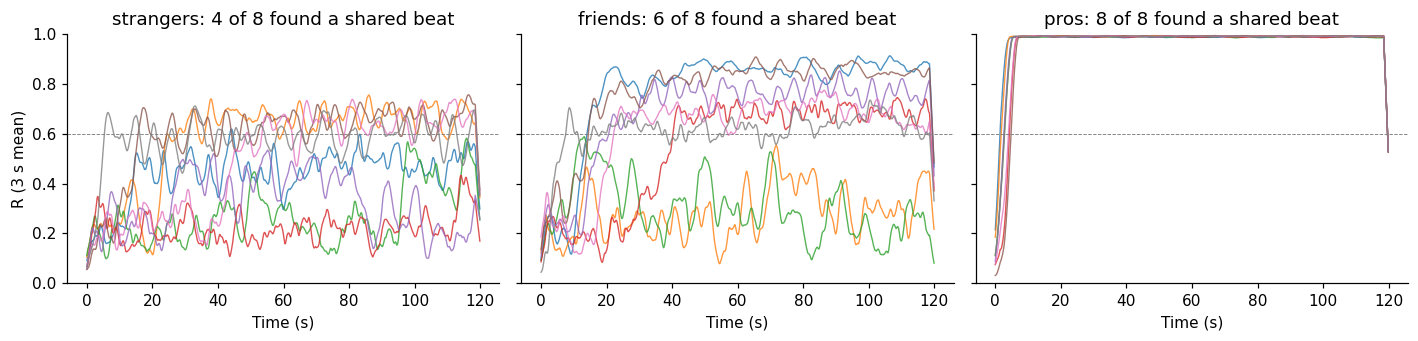

In [5]:
seeds = range(8)
results = {}
for g in ['strangers', 'friends', 'pros']:
    runs = [DanceFloor(g, seed=s).run(120)['R'] for s in seeds]
    results[g] = np.array(runs)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
t = np.arange(results['pros'].shape[1]) * 0.1
for ax, (g, Rs) in zip(axes, results.items()):
    for R in Rs:
        ax.plot(t, np.convolve(R, np.ones(30) / 30, 'same'), lw=0.9, alpha=0.8)
    found = (Rs[:, 600:].mean(1) > 0.55).sum()
    ax.set_title(f'{g}: {found} of {len(Rs)} found a shared beat')
    ax.axhline(0.6, color='gray', ls='--', lw=0.6); ax.set_xlabel('Time (s)')
axes[0].set_ylabel('R (3 s mean)'); axes[0].set_ylim(0, 1)
plt.tight_layout(); plt.show()

# The fog experiment

This has a group dance for a minute, releases fog at some point, and reports an impact analysis.

Example:

- Professional dancers held together: R dipped only from 0.99 to 0.97.

- Strangers dropped from 0.59 to 0.45 and recovered in under a second.

- Friends in that seed weren’t synchronized before the fog.

Change where=(x, z) to put the fog somewhere else on the floor. The floor runs from −2.2 to 2.2.

In [6]:
def fog_experiment(group='pros', seed=0, warmup=60, where=(0.0, 0.0), after=40):
    m = DanceFloor(group, seed=seed)
    before = m.run(warmup)
    R0 = before['R'][-30:].mean()
    near = np.linalg.norm(m.x - np.array(where), axis=1) < 1
    L0 = m.loc[near].mean() if near.any() else np.nan
    m.add_fog(*where)
    rec = {'R': [], 'Lfog': [], 't': []}
    for k in range(int(after / DT)):
        m.step()
        if (k + 1) % 5 == 0:
            m.local_measures()
            rec['R'].append(m.R); rec['Lfog'].append(m.loc[near].mean() if near.any() else np.nan); rec['t'].append(k * DT)
    R = np.array(rec['R']); t = np.array(rec['t'])
    if R0 > 0.45:
        drop = np.where(R < 0.8 * R0)[0]
        if not len(drop):
            outcome = 'held together'
        else:
            back = np.where((t > t[drop[0]]) & (R >= 0.9 * R0))[0]
            outcome = f'recovered after {t[back[0]] - t[drop[0]]:.1f} s' if len(back) else 'tipped into the other state'
    else:
        outcome = 'not synchronized before'
    print(f'{group}: {near.sum()} dancers in the fog. R {R0:.2f} before, lowest {R.min():.2f}. '
          f'Fog dancers local synchrony {L0:.2f} before, lowest {np.nanmin(rec["Lfog"]):.2f}. Outcome: {outcome}.')
    return m, rec

for g in ['pros', 'friends', 'strangers']:
    fog_experiment(g, seed=1)

pros: 16 dancers in the fog. R 0.99 before, lowest 0.97. Fog dancers local synchrony 0.99 before, lowest 0.98. Outcome: held together.
friends: 13 dancers in the fog. R 0.22 before, lowest 0.02. Fog dancers local synchrony 0.25 before, lowest 0.14. Outcome: not synchronized before.
strangers: 13 dancers in the fog. R 0.59 before, lowest 0.45. Fog dancers local synchrony 0.53 before, lowest 0.48. Outcome: recovered after 0.7 s.


# The sweep and hysteresis

This is a sweep run four times at three song memories. Coupling goes up from 0 to 2.6 over a minute and falls back down. The yellow branches are rising and the teal branches are falling. Each panel’s title shows how much higher the coupling is when the group enters synchrony than when it leaves. 

In an example run the gaps were 0.42, 0.61 and 0.44.

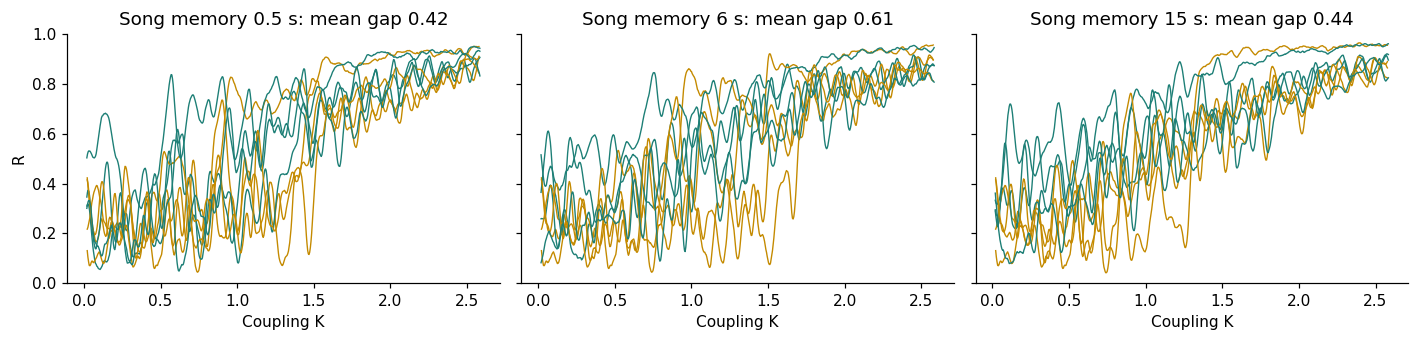

In [7]:
def sweep(mem=6.0, seed=0, Kmax=2.6, half=60):
    m = DanceFloor('custom', seed=seed, adaptive=False, K=0.0, sigma=0.25, J=0.5, noise=0.08, F=1.1, mem=mem)
    m.th = m.rng.random(m.P['N']) * TAU
    ramp_K = lambda s: Kmax * s / half if s < half else Kmax * (2 - s / half)
    out = m.run(2 * half, sweep=ramp_K)
    up = out['t'] < half
    return out['K'][up], out['R'][up], out['K'][~up], out['R'][~up]

def crossing(K, R, rising=True, level=0.6):
    Rs = np.convolve(R, np.ones(9) / 9, 'same')
    idx = np.where(Rs > level)[0]
    if not len(idx): return np.nan
    return K[idx[0]] if rising else K[idx[-1]]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, mem in zip(axes, [0.5, 6, 15]):
    gaps = []
    for seed in range(4):
        Ku, Ru, Kd, Rd = sweep(mem=mem, seed=seed)
        sm = lambda r: np.convolve(r, np.ones(9) / 9, 'same')
        ax.plot(Ku[4:-4], sm(Ru)[4:-4], color='#c48a00', lw=0.9)
        ax.plot(Kd[4:-4], sm(Rd)[4:-4], color='#1d7f76', lw=0.9)
        gaps.append(crossing(Ku, Ru, True) - crossing(Kd, Rd, False))
    ax.set_title(f'Song memory {mem} s: mean gap {np.nanmean(gaps):.2f}')
    ax.set_xlabel('Coupling K')
axes[0].set_ylabel('R'); axes[0].set_ylim(0, 1)
plt.tight_layout(); plt.show()

# Early warning and the landscape

early_warning(R) gives the variance of R and its autocorrelation at a 1-second lag, in a sliding 15-second window.
quasi_potential(R) gives U(R) = −ln p(R).

Both take any R series.

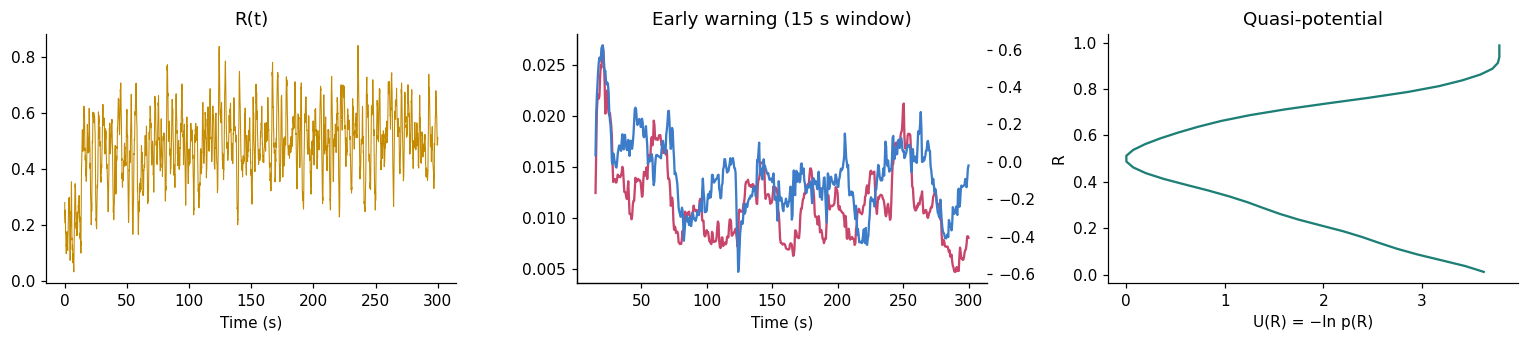

In [8]:
def early_warning(R, window=150, lag=10, step=5):
    ends, var, ac = [], [], []
    for e in range(window, len(R) + 1, step):
        w = R[e - window:e] - R[e - window:e].mean()
        v = (w ** 2).mean()
        ends.append(e); var.append(v); ac.append((w[lag:] * w[:-lag]).mean() / v if v else 0)
    return np.array(ends) * 0.1, np.array(var), np.array(ac)

def quasi_potential(R, bins=40):
    h, edges = np.histogram(R, bins=bins, range=(0, 1))
    k = np.exp(-np.arange(-3, 4) ** 2 / 4)
    hs = np.convolve(h, k / k.sum(), 'same')
    U = -np.log(hs / hs.sum() + 2e-3)
    return (edges[:-1] + edges[1:]) / 2, U - U.min()

out = DanceFloor('strangers', seed=0).run(300)
te, var, ac = early_warning(out['R'])
centers, U = quasi_potential(out['R'])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].plot(out['t'], out['R'], color='#c48a00', lw=0.7); ax[0].set_title('R(t)'); ax[0].set_xlabel('Time (s)')
ax[1].plot(te, var, color='#c8456b', label='Variance'); ax1b = ax[1].twinx()
ax1b.plot(te, ac, color='#3d7cc9', label='Autocorrelation at 1 s'); ax[1].set_title('Early warning (15 s window)')
ax[1].set_xlabel('Time (s)')
ax[2].plot(U, centers, color='#1d7f76'); ax[2].set_xlabel('U(R) = −ln p(R)'); ax[2].set_ylabel('R'); ax[2].set_title('Quasi-potential')
plt.tight_layout(); plt.show()

# Some additional options

- Change a parameter for one run by naming it, for example DanceFloor('strangers', seed=2, mem=15, F=1.0). Every name in BASE can be overridden.
- Switch the movement rule with mode='couzin', and turn on travel with v0=0.3.
- Results vary by seed, so for any comparison, average over several seeds.